# NLP Project for Disaster Tweet Classification

## Step 1. Project Overview

### 1.1 Project Background

Social media platforms such as Twitter can provide useful information during disasters and emergencies. However, not every tweet containing words such as fire, flood, or explosion is actually reporting a real disaster.

In this project, we will build an NLP-based machine learning model that learns from a hand-classified disaster tweet dataset and predicts whether a new tweet is related to a real disaster or not.

### 1.2 Problem Statement
The objective is to classify tweets into two categories:

* 0 → Non-Disaster Tweet
* 1 → Disaster Tweet

The model should learn the language patterns and context of tweets rather than relying only on individual disaster-related keywords.

### 1.3 Project Objectives
* Explore and understand the disaster tweet dataset.
* Clean and preprocess tweet text.
* Extract meaningful NLP features using techniques such as TF-IDF.
* Build and compare classification models.
* Evaluate models using accuracy, precision, recall, and F1-score.
* Validate the final model on unseen data.
* Save the final model for deployment.
* Develop a web interface for predicting disaster-related tweets.

## Step 2. Import Libraries

### 2.1 Import Required Libraries
Before working with the tweet dataset, we import the libraries required for data analysis, visualization, text preprocessing, feature extraction, and machine learning.

In [184]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text preprocessing
import re
import nltk

# Suppress warnings
import warnings
warnings.filterwarnings("ignore")

### 2.2 Download Required NLTK Resources
We download the NLTK resources required for tokenization. These resources allow us to split cleaned tweet text into individual words during the preprocessing stage.

In [185]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Step 3. Load Dataset
Now we load the disaster tweet dataset into a Pandas DataFrame. This dataset contains the hand-classified tweets that will be used for exploration, preprocessing, and model development.

In [186]:
df = pd.read_csv("disaster_tweets.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


In [187]:
df

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1
...,...,...,...,...,...
7608,10869,NaN,NaN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NaN,NaN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided ...,1


## Step 4. Basic Data Exploration

Now the dataset is loaded, we first understand its basic structure before performing any cleaning or analysis.

We will check the first and last records, dataset dimensions, column names, data types, summary statistics, and identify the role of each column.

### 4.1 Display Dataset

In [188]:
# Display first 5 rows
df.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


In [189]:
# Display last 5 rows
df.tail()

,id,keyword,location,text,target
7608,10869,NaN,NaN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NaN,NaN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided ...,1
7612,10873,NaN,NaN,The Latest: More Homes Razed by Northern Calif...,1


### 4.2 Dataset Shape
First, we check the number of rows and columns so we know the size of the dataset we are working with.

In [190]:
df.shape

(7613, 5)

### 4.3 Column Names
Next, we check the column names to understand what information is available in the dataset.

In [191]:
df.columns

Index(['id', 'keyword', 'location', 'text', 'target'], dtype='object')

### 4.4 Dataset Information
Now we check the data types and non-null values of each column. This helps us identify text columns, numerical columns, and columns that contain missing data.

In [192]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   object
 2   location  5079 non-null   object
 3   text      7613 non-null   object
 4   target    7613 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 297.5+ KB


### 4.5 Statistical Summary

To understand the categorical and text columns, we generate a statistical summary showing their count, number of unique values, most frequent value, and its frequency.

In [193]:
categorical_columns = df.select_dtypes(include="object").columns
df[categorical_columns].describe()

,keyword,location,text
count,7552,5079,7613
unique,221,3293,7503
top,fatalities,USA,11-Year-Old Boy Charged With Manslaughter of T...
freq,45,105,10


### 4.6 Identify Features
Before moving into EDA, we identify the numerical and categorical/text columns dynamically. This helps us understand which columns can be used for analysis and which column is our target.

In [194]:
numerical_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include="object").columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical/Text Columns:")
print(list(categorical_columns))

Numerical Columns:
['id', 'target']

Categorical/Text Columns:
['keyword', 'location', 'text']


Observation

* The dataset contains 7,613 tweets with 5 columns: id, keyword, location, text, and target.
* keyword and location contain missing values, while text and target are complete.
* The dataset contains 7,503 unique tweet texts, showing that most tweets have different content.
* id is an identifier, while text, keyword, and location contain the main information for further analysis.
* The target column is the classification label for disaster and non-disaster tweets.

## Step 5. Exploratory Data Analysis (EDA)

### 5.1 Data Quality Analysis

Before analyzing the tweet content, we check the dataset for missing values, duplicate records, and the number of unique values in each column. This helps us understand the overall data quality and identify issues that may need to be handled during preprocessing.

In [195]:
# Check missing values and their percentage
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary

,Missing Values,Missing Percentage
id,0,0.00
keyword,61,0.80
location,2534,33.29
text,0,0.00
target,0,0.00


In [196]:
# Check duplicate records and unique values
duplicate_count = df.duplicated().sum()
print("Duplicate Records:", duplicate_count)

unique_summary = df.nunique()
unique_summary

Duplicate Records: 0


,0
id,7613
keyword,221
location,3293
text,7503
target,2


Observation

* keyword has 61 missing values, while location has 2,534 missing values.
* text and target have no missing values.
* No duplicate records are present.
* The dataset contains 221 unique keywords, 3,293 locations, and 7,503 unique tweets.



### 5.2 Target Variable Analysis

Since this is a binary classification problem, we first examine the distribution of the target classes. This helps us understand whether disaster and non-disaster tweets are reasonably balanced before building the classification models.

In [197]:
# Calculate target counts and percentages
target_counts = df["target"].value_counts().sort_index()

target_percentage = (
    df["target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("Target Distribution:")
print(target_counts)

print("\nTarget Percentage:")
print(target_percentage)

Target Distribution:
target
0    4342
1    3271
Name: count, dtype: int64

Target Percentage:
target
0    57.03
1    42.97
Name: proportion, dtype: float64


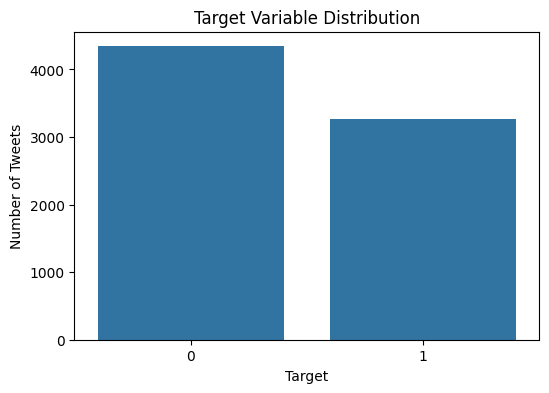

In [198]:
# Visualize target distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="target")

plt.title("Target Variable Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Tweets")

plt.show()

Observation
* The dataset contains 4,342 non-disaster tweets (0) and 3,271 disaster tweets (1).
* Non-disaster tweets represent 57.03%, while disaster tweets represent 42.97%.
* The classes are moderately imbalanced, with more non-disaster tweets.

### 5.3 Keyword Analysis
Keywords provide an initial indication of the topics associated with the tweets. We analyze the most frequent keywords and examine how they are distributed across disaster and non-disaster tweets.

In [199]:
# Find the most frequent keywords
top_keywords = df["keyword"].value_counts().head(20)

print("Top 20 Most Frequent Keywords:")
print(top_keywords)

Top 20 Most Frequent Keywords:
keyword
fatalities     45
deluge         42
armageddon     42
damage         41
body%20bags    41
harm           41
sinking        41
evacuate       40
outbreak       40
fear           40
siren          40
windstorm      40
collided       40
twister        40
hellfire       39
famine         39
flames         39
weapon         39
wreckage       39
sunk           39
Name: count, dtype: int64


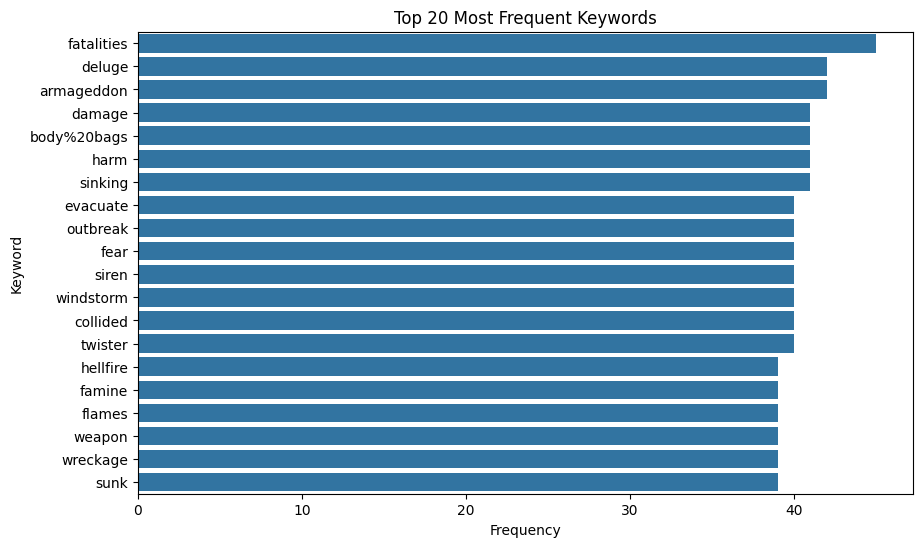

In [200]:
# Visualize the most frequent keywords
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_keywords.values,
    y=top_keywords.index
)

plt.title("Top 20 Most Frequent Keywords")
plt.xlabel("Frequency")
plt.ylabel("Keyword")

plt.show()

In [201]:
# Analyze keywords by target
keyword_target = pd.crosstab(
    df["keyword"],
    df["target"]
)

keyword_target["Total"] = keyword_target.sum(axis=1)

keyword_target.sort_values(
    by="Total",
    ascending=False
).head(20)

target,0,1,Total
keyword,,,
fatalities,19,26,45
deluge,36,6,42
armageddon,37,5,42
damage,22,19,41
body%20bags,40,1,41
harm,37,4,41
sinking,33,8,41
evacuate,15,25,40
outbreak,1,39,40


In [202]:
# Compare the most frequent keywords in each target class
disaster_keywords = (
    df[df["target"] == 1]["keyword"]
    .value_counts()
    .head(15)
)

non_disaster_keywords = (
    df[df["target"] == 0]["keyword"]
    .value_counts()
    .head(15)

)

print("Top Disaster Tweet Keywords:")
print(disaster_keywords)

print("\nTop Non-Disaster Tweet Keywords:")
print(non_disaster_keywords)

Top Disaster Tweet Keywords:
keyword
derailment             39
outbreak               39
wreckage               39
debris                 37
oil%20spill            37
typhoon                37
rescuers               32
suicide%20bomb         32
suicide%20bombing      32
evacuated              32
nuclear%20disaster     31
razed                  31
airplane%20accident    30
suicide%20bomber       30
earthquake             30
Name: count, dtype: int64

Top Non-Disaster Tweet Keywords:
keyword
body%20bags    40
armageddon     37
harm           37
deluge         36
ruin           36
wrecked        36
explode        35
fear           35
twister        35
siren          35
panic          34
aftershock     34
screaming      34
blizzard       33
blazing        33
Name: count, dtype: int64


Observation
* The dataset contains 221 unique keywords, with keywords such as fatalities, deluge, and armageddon appearing frequently.
* Keyword usage differs between disaster and non-disaster tweets.
* Some keywords appear more frequently in one target class, such as outbreak and wreckage in disaster tweets.
* This shows that keywords can provide useful information for distinguishing between the two classes.
* These findings provide useful exploratory context; however, the final model uses cleaned tweet text rather than keyword or location columns as input.

### 5.4 Location Analysis
Location information may provide additional context about where tweets originate. We examine the most frequently occurring locations and their relationship with the target classes.

In [203]:
# Find the most frequent locations
top_locations = df["location"].value_counts().head(20)

print("Top 20 Tweet Locations:")
print(top_locations)

Top 20 Tweet Locations:
location
USA                105
New York            73
United States       50
London              46
Nigeria             32
Canada              30
UK                  27
Los Angeles, CA     26
India               24
Mumbai              22
Washington, DC      21
California          20
Kenya               20
Worldwide           19
Australia           19
Chicago, IL         18
New York, NY        15
Los Angeles         15
Everywhere          15
California, USA     15
Name: count, dtype: int64


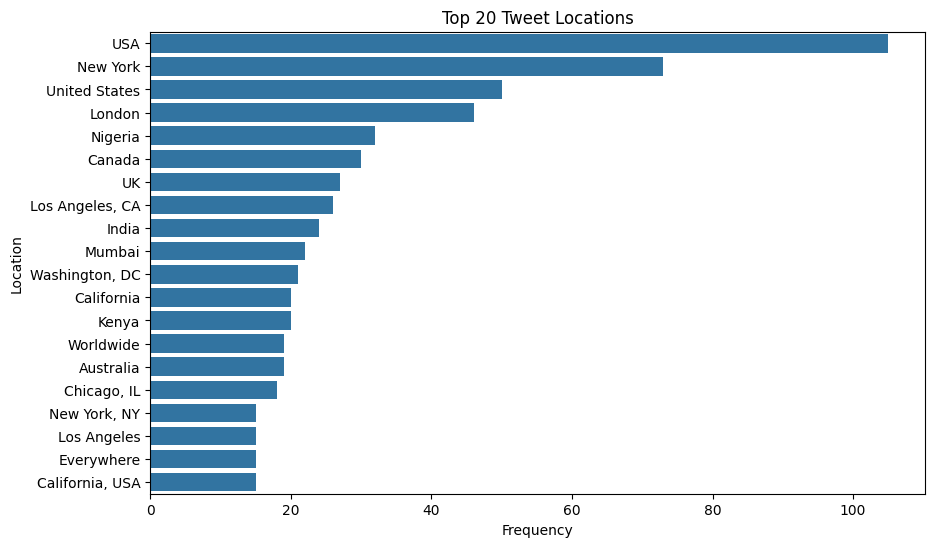

In [204]:
# Visualize the most frequent locations
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_locations.values,
    y=top_locations.index
)

plt.title("Top 20 Tweet Locations")
plt.xlabel("Frequency")
plt.ylabel("Location")

plt.show()

In [205]:
# Analyze location by target
location_target = pd.crosstab(
    df["location"],
    df["target"]
)

location_target["Total"] = location_target.sum(axis=1)

location_target.sort_values(
    by="Total",
    ascending=False
).head(20)

target,0,1,Total
location,,,
USA,38,67,105
New York,56,17,73
United States,23,27,50
London,30,16,46
Nigeria,6,26,32
Canada,17,13,30
UK,11,16,27
"Los Angeles, CA",18,8,26
India,4,20,24


Observation
* The dataset contains 3,293 unique locations, with USA, New York, and United States among the most frequent.
* The distribution of disaster and non-disaster tweets varies across locations.
* Many locations have relatively few tweets, so location may provide additional context but may not be a strong standalone feature.

### 5.5 Tweet Text Analysis
Since the main objective is to classify tweets based on their content, we examine basic characteristics of the tweet text. Tweet length, word count, hashtags, mentions, and URLs can provide additional information about the structure of disaster and non-disaster tweets.

In [206]:
# Create basic text-based features
df["tweet_length"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()
df["hashtag_count"] = df["text"].str.count(r"#\w+")
df["mention_count"] = df["text"].str.count(r"@\w+")
df["url_count"] = df["text"].str.count(r"https?://\S+")

text_features = [
    "tweet_length",
    "word_count",
    "hashtag_count",
    "mention_count",
    "url_count"
]

df[text_features].describe()

,tweet_length,word_count,hashtag_count,mention_count,url_count
count,7613.000000,7613.000000,7613.000000,7613.000000,7613.000000
mean,101.018390,14.903455,0.437410,0.356627,0.620123
std,33.780176,5.732705,1.085629,0.714569,0.663930
min,7.000000,1.000000,0.000000,0.000000,0.000000
25%,77.000000,11.000000,0.000000,0.000000,0.000000
50%,107.000000,15.000000,0.000000,0.000000,1.000000
75%,133.000000,19.000000,0.000000,1.000000,1.000000
max,157.000000,31.000000,13.000000,8.000000,4.000000


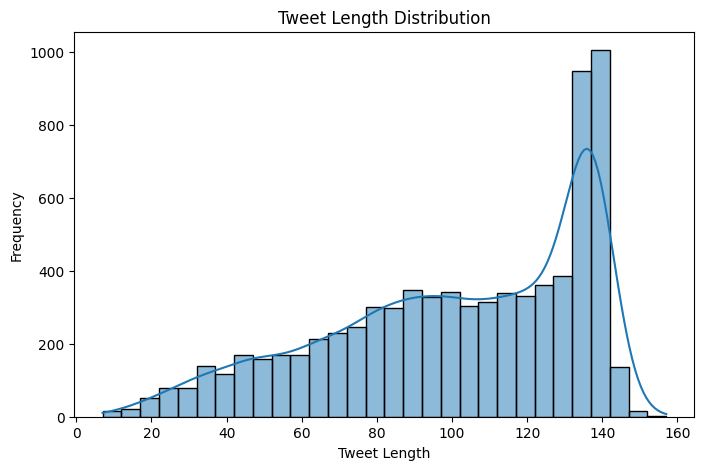

In [207]:
# Analyze tweet length distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tweet_length",
    bins=30,
    kde=True
)

plt.title("Tweet Length Distribution")
plt.xlabel("Tweet Length")
plt.ylabel("Frequency")

plt.show()

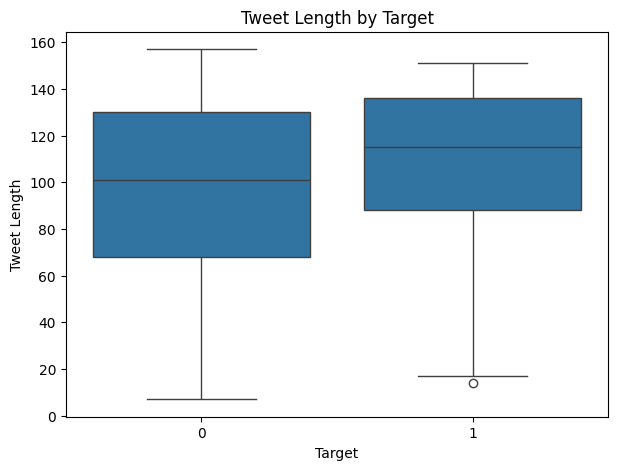

In [208]:
# Compare tweet length across target classes
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="target",
    y="tweet_length"
)

plt.title("Tweet Length by Target")
plt.xlabel("Target")
plt.ylabel("Tweet Length")

plt.show()

Observation
* The average tweet length is about 101 characters, with an average of 15 words per tweet.
* Disaster tweets (1) generally have a higher median tweet length than non-disaster tweets (0).

### 5.6 Word Frequency Analysis
To understand the vocabulary used in the tweets, we analyze the most frequently occurring words overall and compare the vocabulary of disaster and non-disaster tweets.

In [209]:
from collections import Counter

# Calculate overall word frequency
all_words = " ".join(
    df["text"].astype(str)
).lower().split()

word_frequency = Counter(all_words)

top_words = pd.DataFrame(
    word_frequency.most_common(20),
    columns=["Word", "Frequency"]
)

top_words

,Word,Frequency
0,the,3219
1,a,2137
2,in,1949
3,to,1934
4,of,1814
5,and,1405
6,i,1344
7,is,930
8,for,880
9,on,834


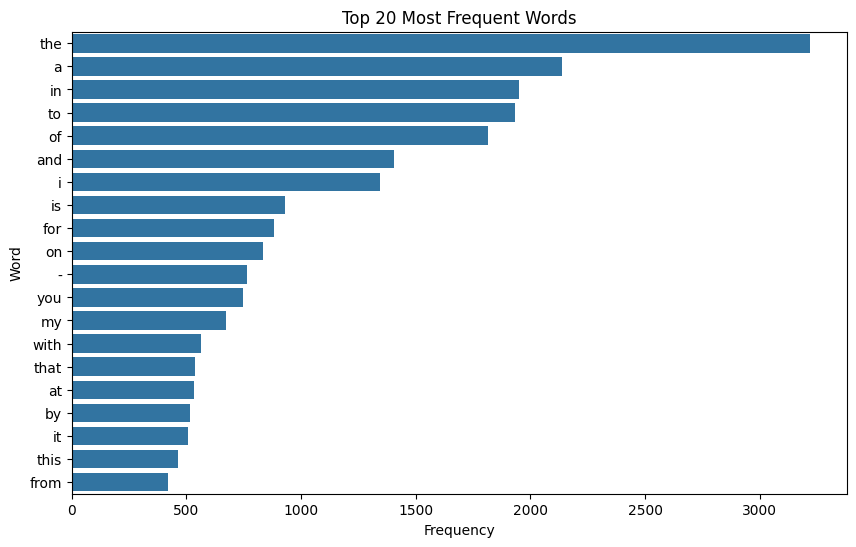

In [210]:
# Visualize the most frequent words
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_words,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.show()

In [211]:
# Compare word frequencies between disaster and non-disaster tweets
disaster_words = " ".join(
    df[df["target"] == 1]["text"].astype(str)
).lower().split()

non_disaster_words = " ".join(
    df[df["target"] == 0]["text"].astype(str)
).lower().split()

disaster_word_frequency = Counter(disaster_words)
non_disaster_word_frequency = Counter(non_disaster_words)

print("Top Disaster Tweet Words:")
print(disaster_word_frequency.most_common(20))

print("\nTop Non-Disaster Tweet Words:")
print(non_disaster_word_frequency.most_common(20))

Top Disaster Tweet Words:
[('the', 1336), ('in', 1144), ('of', 919), ('a', 897), ('to', 753), ('and', 494), ('on', 410), ('for', 394), ('-', 389), ('is', 344), ('at', 303), ('i', 286), ('by', 274), ('from', 243), ('with', 188), ('that', 181), ('after', 181), ('this', 177), ('as', 167), ('are', 166)]

Top Non-Disaster Tweet Words:
[('the', 1883), ('a', 1240), ('to', 1181), ('i', 1058), ('and', 911), ('of', 895), ('in', 805), ('you', 627), ('is', 586), ('my', 543), ('for', 486), ('on', 424), ('with', 374), ('-', 374), ('that', 357), ('it', 343), ('this', 286), ('be', 284), ('like', 250), ('by', 242)]


Observation
* Common words such as the, a, in, to, and of appear most frequently in the tweets.
* Disaster and non-disaster tweets show differences in their word frequency patterns.
* Many of the most frequent words are common English words, so text preprocessing such as stopword removal will be useful before feature extraction.

## Step 6. Data Preprocessing
Now we will prepare the dataset for machine learning. We will select the relevant columns, handle missing values, clean the tweet text, and prepare the target variable.

### 6.1 Select Required Features
We select keyword, location, and text for preprocessing and exploratory analysis. The id column is excluded because it is only an identifier. For model training, we will use the cleaned tweet text as the input feature, while keyword and location will remain useful for exploration.

In [212]:
# Select input features and target
feature_columns = ["keyword", "location", "text"]

X = df[feature_columns].copy()
y = df["target"].copy()

print("Feature Columns:")
print(list(X.columns))

print("\nTarget Column:")
print(y.name)

Feature Columns:
['keyword', 'location', 'text']

Target Column:
target


### 6.2 Handle Missing Values
The keyword and location columns contain missing values, while the text column is complete. Since a missing keyword or location simply means that this information is unavailable, we replace the missing values with an empty string instead of removing those records. This allows us to keep all tweets in the dataset.

In [213]:
# Check missing values before handling them
print("Missing values before handling:")
print(X.isnull().sum())

# Replace missing keyword and location values with empty strings
X["keyword"] = X["keyword"].fillna("")
X["location"] = X["location"].fillna("")

# Check missing values after handling them
print("\nMissing values after handling:")
print(X.isnull().sum())

Missing values before handling:
keyword       61
location    2534
text           0
dtype: int64

Missing values after handling:
keyword     0
location    0
text        0
dtype: int64


### 6.3 Clean Tweet Text
Tweets often contain URLs, mentions, hashtags, punctuation, special characters, and inconsistent capitalization. Cleaning these elements helps reduce unnecessary noise and prepares the text for tokenization and TF-IDF feature extraction.

In [214]:
# Function to clean tweet text
def clean_text(text):
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Remove hashtag symbol but keep the word
    text = re.sub(r"#", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply text cleaning
X["cleaned_text"] = X["text"].apply(clean_text)

# Display original and cleaned text
X[["text", "cleaned_text"]].head()

,text,cleaned_text
0,Our Deeds are the Reason of this #earthquake M...,our deeds are the reason of this earthquake ma...
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada
2,All residents asked to 'shelter in place' are ...,all residents asked to shelter in place are be...
3,"13,000 people receive #wildfires evacuation or...",people receive wildfires evacuation orders in ...
4,Just got sent this photo from Ruby #Alaska as ...,just got sent this photo from ruby alaska as s...


### 6.4 Tokenization
After cleaning the tweets, we split each tweet into individual words called tokens. Tokenization is demonstrated as part of the NLP preprocessing workflow and prepares the text for word-level processing. The tokenized column is used for demonstration, while TF-IDF later processes the cleaned text directly during feature extraction.

In [215]:
# Tokenize the cleaned tweet text
X["tokens"] = X["cleaned_text"].apply(nltk.word_tokenize)

# Display original cleaned text and tokens
X[["cleaned_text", "tokens"]].head()

,cleaned_text,tokens
0,our deeds are the reason of this earthquake ma...,"[our, deeds, are, the, reason, of, this, earth..."
1,forest fire near la ronge sask canada,"[forest, fire, near, la, ronge, sask, canada]"
2,all residents asked to shelter in place are be...,"[all, residents, asked, to, shelter, in, place..."
3,people receive wildfires evacuation orders in ...,"[people, receive, wildfires, evacuation, order..."
4,just got sent this photo from ruby alaska as s...,"[just, got, sent, this, photo, from, ruby, ala..."


### 6.5 Prepare Target Variable
The target variable represents the class that the model needs to predict. We keep it as a binary numerical variable where 0 represents a non-disaster tweet and 1 represents a disaster tweet.

In [216]:
# Check target values
print("Unique Target Values:")
print(y.unique())

# Display target distribution
print("\nTarget Distribution:")
print(y.value_counts())

Unique Target Values:
[1 0]

Target Distribution:
target
0    4342
1    3271
Name: count, dtype: int64


Observation:
* The required input features keyword, location, and text were selected, while id was excluded because it is only an identifier.
* Missing values in keyword and location were replaced with empty strings, allowing all 7,613 tweets to be retained.
* Tweet text was cleaned by removing URLs, mentions, unnecessary special characters, and extra spaces while preserving meaningful words.
* The cleaned tweets were tokenized into individual words for NLP processing.
* The target variable contains two classes: 0 for non-disaster tweets and 1 for disaster tweets, confirming that this is a binary classification problem.

## Step 7. Train-Test Split

### 7.1 Separate Features and Target
Before splitting the dataset, we define the text input that will be used for machine learning and separate it from the target variable. The cleaned tweet text will be the main input for TF-IDF feature extraction, while target will be the output that the models learn to predict.

In [217]:
# Define input text and target
X_text = X["cleaned_text"]
y = df["target"]

# Check the shapes
print("Text Data Shape:", X_text.shape)
print("Target Shape:", y.shape)

Text Data Shape: (7613,)
Target Shape: (7613,)


### 7.2 Split Dataset
Now we split the dataset into training and testing sets. The training data will be used to learn patterns from the tweets, while the testing data will be used later to evaluate how well the model performs on unseen tweets.

We use an 80:20 split and stratify=y so that both training and testing sets maintain a similar proportion of disaster and non-disaster tweets.

In [218]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 6090
Testing Samples: 1523


### 7.3 Verify Training and Testing Data
Before moving to feature extraction, we verify that the training and testing datasets contain the expected number of samples and that both target classes are represented in each set.

In [219]:
# Check training and testing shapes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Check target distribution in both sets
print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Data Shape: (6090,)
Testing Data Shape: (1523,)

Training Target Distribution:
target
0    3473
1    2617
Name: count, dtype: int64

Testing Target Distribution:
target
0    869
1    654
Name: count, dtype: int64


Observation:
* The cleaned tweet text was separated from the target variable for model development.
* The dataset was divided into 80% training data (6,090 tweets) and 20% testing data (1,523 tweets).
* Stratified splitting maintained a similar distribution of disaster and non-disaster tweets in both datasets.
* The testing data remains unseen during model training and will be used for final evaluation.

## Step 8. Feature Engineering
Now we convert the cleaned text into numerical features using TF-IDF (Term Frequency–Inverse Document Frequency).

### 8.1 TF-IDF Feature Extraction
Machine learning models cannot directly understand text. TF-IDF converts tweet text into numerical features by assigning weights to words based on their frequency in a tweet and how common they are across the collection of tweets.

We will fit the TF-IDF vectorizer only on the training tweets and then transform both training and testing tweets. This prevents information from the testing data from leaking into the training process.

In [220]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

# Fit TF-IDF only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data using the same fitted vectorizer
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (6090, 5000)
Testing TF-IDF Shape: (1523, 5000)


Observation:
* The cleaned tweet text was converted into numerical TF-IDF features.
* The training data contains 6,090 tweets and 5,000 TF-IDF features.
* The testing data contains 1,523 tweets with the same 5,000 features.
* TF-IDF was fitted only on the training data and then applied to the testing data, preventing data leakage.
* Stopwords were excluded during feature extraction.

## Step 9. Model Building

### 9.1 Logistic Regression
Logistic Regression is a strong baseline model for text classification. It works well with high-dimensional sparse features such as TF-IDF and provides a simple benchmark for comparing the more complex models.

In [221]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### 9.2 Random Forest Classifier
Random Forest is an ensemble classification algorithm that combines multiple decision trees to make predictions. We will train it using the TF-IDF features and later compare its performance with Logistic Regression and Neural Network models.

In [222]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_tfidf, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### 9.3 Neural Network Classifier
The third model is a Neural Network classifier. We use MLPClassifier from scikit-learn, which can learn nonlinear patterns from the TF-IDF features. This gives us another model to compare against Logistic Regression and Random Forest.

In [223]:
from sklearn.neural_network import MLPClassifier

# Create Neural Network model
mlp_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=100,
    random_state=42,
    early_stopping=True
)

# Train the model
mlp_model.fit(X_train_tfidf, y_train)

print("Neural Network model trained successfully.")

Neural Network model trained successfully.


Observation:
* Three classification models were successfully trained using the TF-IDF features.
* Logistic Regression provides a baseline for text classification.
* Random Forest provides an ensemble-based approach using multiple decision trees.
* Neural Network provides a nonlinear learning approach.
* These models will now be evaluated on the unseen testing data to compare their classification performance.
* These initial models provide a baseline for comparison before hyperparameter tuning.

## Step 10. Model Evaluation

### 10.1 Evaluation Metrics
After training the models, we need to measure how well they classify unseen tweets. We will use accuracy, precision, recall, and F1-score. These metrics provide different views of classification performance, which is especially useful because our dataset has somewhat more non-disaster than disaster tweets.

In [224]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Evaluation metrics imported successfully.")

Evaluation metrics imported successfully.


### 10.2 Evaluate Models
Now we use the trained models to predict the classes of the unseen testing tweets. We then calculate accuracy, precision, recall, and F1-score for each model so that their performance can be compared using the same evaluation criteria.

In [225]:
# Generate predictions on the testing data
lr_pred = lr_model.predict(X_test_tfidf)
rf_pred = rf_model.predict(X_test_tfidf)
mlp_pred = mlp_model.predict(X_test_tfidf)

# Calculate evaluation metrics
results = []

models = {
    "Logistic Regression": lr_pred,
    "Random Forest": rf_pred,
    "Neural Network": mlp_pred
}

for model_name, predictions in models.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions)
    })

# Create comparison DataFrame
evaluation_df = pd.DataFrame(results)

evaluation_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.825345,0.855311,0.714067,0.778333
1,Random Forest,0.793828,0.795139,0.700306,0.744715
2,Neural Network,0.818122,0.815745,0.744648,0.778577


### 10.3 Model Comparison
A visual comparison makes it easier to examine how the three models perform across accuracy, precision, recall, and F1-score.

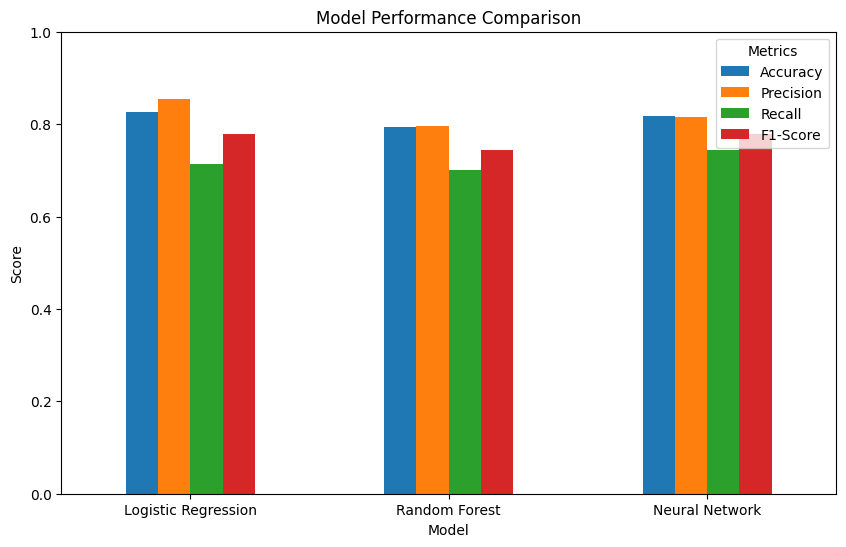

In [226]:
# Plot model performance comparison
evaluation_plot = evaluation_df.set_index("Model")

evaluation_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")

plt.show()

### 10.4 Cross-Validation

We use 5-fold stratified cross-validation to evaluate how consistently each model performs across different subsets of the training data. The training data is divided into five folds, and each fold is used for validation once while the remaining folds are used for training.

TF-IDF and the classifier are placed inside a Pipeline so that the TF-IDF vectorizer is fitted separately during each fold. This prevents validation data from influencing the text features used to train that fold's model.

In [227]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create pipelines for cross-validation
models_for_cv = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            stop_words="english"
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            stop_words="english"
        )),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Neural Network": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            stop_words="english"
        )),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(100,),
            max_iter=100,
            random_state=42,
            early_stopping=True
        ))
    ])
}

# Store cross-validation results
cv_results = []

for model_name, model in models_for_cv.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    cv_results.append({
        "Model": model_name,
        "Mean F1-Score": scores.mean(),
        "Std F1-Score": scores.std()
    })

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results)

cv_results_df

,Model,Mean F1-Score,Std F1-Score
0,Logistic Regression,0.734528,0.005815
1,Random Forest,0.722538,0.018549
2,Neural Network,0.739584,0.015052


Observations:
- Neural Network achieved the highest mean cross-validation F1-score of **0.7396**, followed by Logistic Regression at **0.7345**.
- Random Forest achieved a mean F1-score of **0.7225**.
- Logistic Regression showed the lowest variation across folds, with a standard deviation of **0.0058**, indicating more consistent performance.
- Cross-validation was performed using pipelines, ensuring TF-IDF was fitted separately within each fold and reducing data leakage.

## Step 11. Hyperparameter Tuning

The initial models were trained using default or manually selected hyperparameters. Hyperparameter tuning helps us test different settings and identify configurations that may improve model performance.

We will tune the models using GridSearchCV with 5-fold cross-validation and use F1-score as the evaluation metric.

### 11.1 Define Parameter Grids

In [228]:
from sklearn.model_selection import GridSearchCV

# Logistic Regression parameters
lr_param_grid = {
    "classifier__C": [0.1, 1, 10]
}

# Random Forest parameters
rf_param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 20],
    "classifier__min_samples_split": [2, 5]
}

# Neural Network parameters
mlp_param_grid = {
    "classifier__hidden_layer_sizes": [(50,), (100,)],
    "classifier__alpha": [0.0001, 0.001],
    "classifier__learning_rate_init": [0.001, 0.01]
}

print("Hyperparameter grids defined successfully.")

Hyperparameter grids defined successfully.


### 11.2 Perform Hyperparameter Tuning
Now we use GridSearchCV to test the defined hyperparameter combinations using 5-fold cross-validation. The model configuration with the highest F1-score will be selected for each algorithm.

#### 11.2.1 Logistic Regression

In [229]:
# Create Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        stop_words="english"
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Create GridSearchCV
lr_grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

# Perform hyperparameter tuning on raw text
lr_grid_search.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")
print(lr_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(lr_grid_search.best_score_)

Best Logistic Regression Parameters:
{'classifier__C': 1}

Best Cross-Validation F1-Score:
0.7345275565980868


#### 11.2.2 Random Forest

In [230]:
# Create Random Forest pipeline
rf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        stop_words="english"
    )),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

# Create GridSearchCV
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=1
)

# Perform hyperparameter tuning on raw text
rf_grid_search.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(rf_grid_search.best_score_)

Best Random Forest Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 200}

Best Cross-Validation F1-Score:
0.7295799288652743


#### 11.2.3 Neural Network

In [231]:
# Create Neural Network pipeline
mlp_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        stop_words="english"
    )),
    ("classifier", MLPClassifier(
        max_iter=100,
        random_state=42,
        early_stopping=True
    ))
])

# Create GridSearchCV
mlp_grid_search = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=mlp_param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

# Perform hyperparameter tuning on raw text
mlp_grid_search.fit(X_train, y_train)

print("Best Neural Network Parameters:")
print(mlp_grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(mlp_grid_search.best_score_)

Best Neural Network Parameters:
{'classifier__alpha': 0.0001, 'classifier__hidden_layer_sizes': (100,), 'classifier__learning_rate_init': 0.001}

Best Cross-Validation F1-Score:
0.7395843080504546


Observations:
- Logistic Regression selected C = 1, with a cross-validation F1-score of **0.7345**.
- Random Forest selected 200 estimators, no maximum depth limit, and a minimum split size of 5, achieving a cross-validation F1-score of **0.7296**.
- Neural Network selected one hidden layer with 100 neurons, alpha = 0.0001, and a learning rate of 0.001, achieving the highest cross-validation F1-score of **0.7396**.
- Neural Network performed best during cross-validation, although final model selection should also consider test performance and overfitting.

### 11.3 Evaluate Tuned Models

In [232]:
# Get the best tuned models
best_lr_model = lr_grid_search.best_estimator_
best_rf_model = rf_grid_search.best_estimator_
best_mlp_model = mlp_grid_search.best_estimator_

# Pipelines accept raw text and apply TF-IDF internally
tuned_lr_pred = best_lr_model.predict(X_test)
tuned_rf_pred = best_rf_model.predict(X_test)
tuned_mlp_pred = best_mlp_model.predict(X_test)

# Evaluate tuned models
tuned_results = []

tuned_models = {
    "Logistic Regression": tuned_lr_pred,
    "Random Forest": tuned_rf_pred,
    "Neural Network": tuned_mlp_pred
}

for model_name, predictions in tuned_models.items():
    tuned_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions)
    })

tuned_evaluation_df = pd.DataFrame(tuned_results)

tuned_evaluation_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.825345,0.855311,0.714067,0.778333
1,Random Forest,0.800394,0.789735,0.729358,0.758347
2,Neural Network,0.818122,0.815745,0.744648,0.778577


**Observations:**
- Logistic Regression achieved the highest accuracy **82.53%** and precision **85.53%**.
- Neural Network achieved the highest recall **74.46%** and F1-score **0.7786**, narrowly outperforming Logistic Regression's F1-score of **0.7783**.
- Random Forest improved its F1-score to **0.7583** after tuning.
- Logistic Regression was more precise, while Neural Network identified a slightly larger proportion of actual disaster tweets.

### 11.4 Compare Before vs After Tuning

In [233]:
# Create comparison of before and after tuning
comparison_results = []

for model_name in ["Logistic Regression", "Random Forest", "Neural Network"]:
    before = evaluation_df[evaluation_df["Model"] == model_name].iloc[0]
    after = tuned_evaluation_df[tuned_evaluation_df["Model"] == model_name].iloc[0]

    comparison_results.append({
        "Model": model_name,
        "Before Tuning F1": before["F1-Score"],
        "After Tuning F1": after["F1-Score"],
        "F1 Improvement": after["F1-Score"] - before["F1-Score"]
    })

tuning_comparison_df = pd.DataFrame(comparison_results)

tuning_comparison_df

,Model,Before Tuning F1,After Tuning F1,F1 Improvement
0,Logistic Regression,0.778333,0.778333,0.000000
1,Random Forest,0.744715,0.758347,0.013631
2,Neural Network,0.778577,0.778577,0.000000


Observations:
- Random Forest improved its F1-score from **0.7447 to 0.7583**, an improvement of approximately **0.0136**.
- Logistic Regression's F1-score remained unchanged at **0.7783**.
- Neural Network's F1-score remained unchanged at **0.7786**.
- Hyperparameter tuning improved Random Forest's performance, while the other models retained their original test F1-scores.

## Step 12. Final Model Validation

### 12.1 Final Classification Performance
Now we'll look at the detailed classification report for each tuned model. This gives class-wise precision, recall, and F1-score instead of only the overall metrics.

In [234]:
print("Logistic Regression Classification Report:")
print(classification_report(y_test, tuned_lr_pred))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, tuned_rf_pred))

print("\nNeural Network Classification Report:")
print(classification_report(y_test, tuned_mlp_pred))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.91      0.86       869
           1       0.86      0.71      0.78       654

    accuracy                           0.83      1523
   macro avg       0.83      0.81      0.82      1523
weighted avg       0.83      0.83      0.82      1523


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.85      0.83       869
           1       0.79      0.73      0.76       654

    accuracy                           0.80      1523
   macro avg       0.80      0.79      0.79      1523
weighted avg       0.80      0.80      0.80      1523


Neural Network Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.87      0.85       869
           1       0.82      0.74      0.78       654

    accuracy                           0.82      1523
   macro

Observations:
- Logistic Regression achieved **83% precision and 91% recall** for non-disaster tweets, but its recall for disaster tweets was lower at **71%**.
- Random Forest achieved **73% recall** for disaster tweets, with an overall accuracy of **80%**.
- Neural Network achieved **74% recall** for disaster tweets and an overall accuracy of **82%**.
- Logistic Regression provided the highest overall accuracy and disaster-class precision, while Neural Network provided slightly better disaster-class recall and F1-score.
- All three models performed better at identifying non-disaster tweets than disaster tweets.

### 12.2 Confusion Matrix

A confusion matrix will show exactly how many tweets were:
* Correctly classified as Non-Disaster
* Incorrectly classified as Disaster
* Incorrectly classified as Non-Disaster
* Correctly classified as Disaster

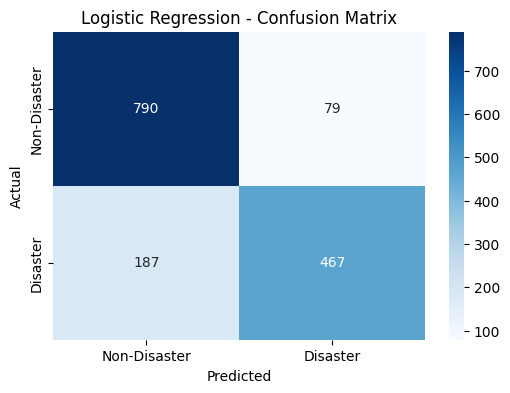

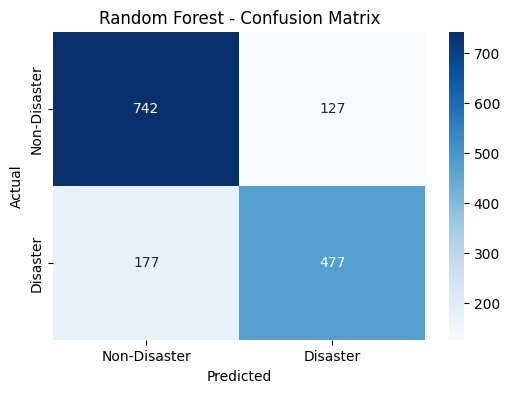

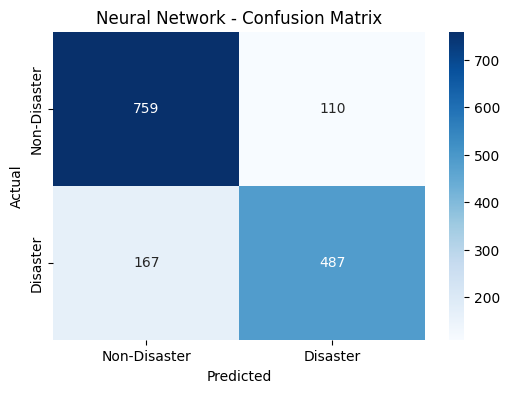

In [235]:
from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
lr_cm = confusion_matrix(y_test, tuned_lr_pred)
rf_cm = confusion_matrix(y_test, tuned_rf_pred)
mlp_cm = confusion_matrix(y_test, tuned_mlp_pred)

# Plot Logistic Regression confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Disaster", "Disaster"],
    yticklabels=["Non-Disaster", "Disaster"]
)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Plot Random Forest confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Disaster", "Disaster"],
    yticklabels=["Non-Disaster", "Disaster"]
)
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Plot Neural Network confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    mlp_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Disaster", "Disaster"],
    yticklabels=["Non-Disaster", "Disaster"]
)
plt.title("Neural Network - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Observations:
- Logistic Regression correctly classified 790 non-disaster tweets and 467 disaster tweets. It missed 187 disaster tweets.
- Random Forest correctly classified 742 non-disaster tweets and 477 disaster tweets. It missed 177 disaster tweets.
- Neural Network correctly classified 759 non-disaster tweets and 487 disaster tweets. It missed 167 disaster tweets.
- Neural Network correctly identified the largest number of disaster tweets and had the fewest missed disaster tweets.
- Logistic Regression produced the fewest false positives, with 79 non-disaster tweets incorrectly classified as disasters.

### 12.3 ROC Curve and ROC-AUC
Now we'll evaluate how well each model separates Disaster vs Non-Disaster across different classification thresholds.

Logistic Regression ROC-AUC: 0.8725
Random Forest ROC-AUC: 0.8591
Neural Network ROC-AUC: 0.8647


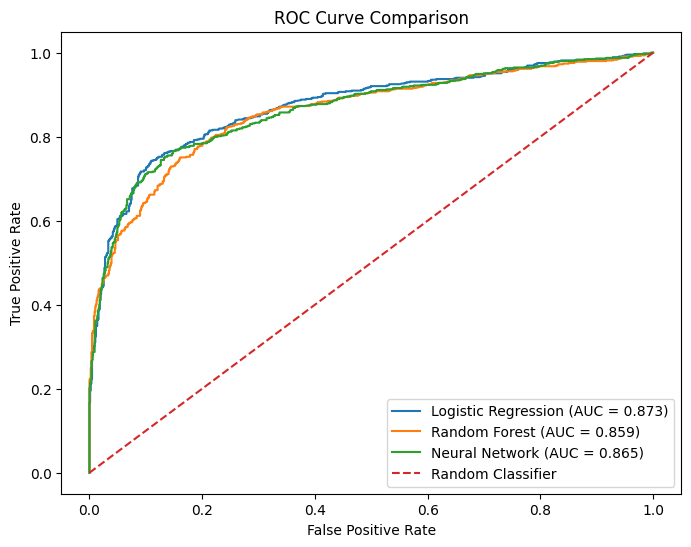

In [236]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get prediction probabilities
lr_prob = best_lr_model.predict_proba(X_test)[:, 1]
rf_prob = best_rf_model.predict_proba(X_test)[:, 1]
mlp_prob = best_mlp_model.predict_proba(X_test)[:, 1]

# Calculate ROC curves
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
mlp_fpr, mlp_tpr, _ = roc_curve(y_test, mlp_prob)

# Calculate ROC-AUC scores
lr_auc = roc_auc_score(y_test, lr_prob)
rf_auc = roc_auc_score(y_test, rf_prob)
mlp_auc = roc_auc_score(y_test, mlp_prob)

print("Logistic Regression ROC-AUC:", round(lr_auc, 4))
print("Random Forest ROC-AUC:", round(rf_auc, 4))
print("Neural Network ROC-AUC:", round(mlp_auc, 4))

# Plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(lr_fpr, lr_tpr, label=f"Logistic Regression (AUC = {lr_auc:.3f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")
plt.plot(mlp_fpr, mlp_tpr, label=f"Neural Network (AUC = {mlp_auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

Observations:
- Logistic Regression achieved the highest ROC-AUC score of **0.8725**.
- Neural Network followed with **0.8647**, while Random Forest achieved **0.8591**.
- Logistic Regression showed the strongest ability to distinguish between disaster and non-disaster tweets across different classification thresholds.

### 12.4 Precision-Recall Curve
Since our main goal is to identify Disaster tweets, the Precision-Recall curve is especially useful. It shows the trade-off between correctly identifying disaster tweets and avoiding incorrect disaster predictions.

Logistic Regression Average Precision: 0.8667
Random Forest Average Precision: 0.8554
Neural Network Average Precision: 0.8613


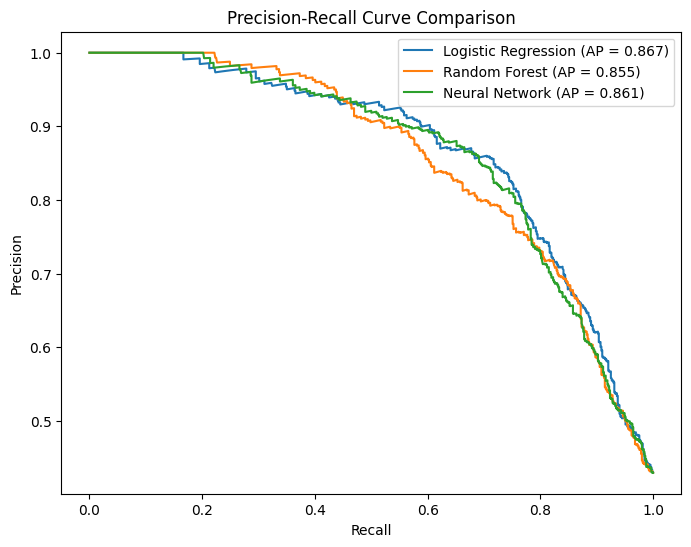

In [237]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision-recall curves
lr_precision, lr_recall, _ = precision_recall_curve(y_test, lr_prob)
rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_prob)
mlp_precision, mlp_recall, _ = precision_recall_curve(y_test, mlp_prob)

# Calculate Average Precision scores
lr_ap = average_precision_score(y_test, lr_prob)
rf_ap = average_precision_score(y_test, rf_prob)
mlp_ap = average_precision_score(y_test, mlp_prob)

print("Logistic Regression Average Precision:", round(lr_ap, 4))
print("Random Forest Average Precision:", round(rf_ap, 4))
print("Neural Network Average Precision:", round(mlp_ap, 4))

# Plot Precision-Recall curves
plt.figure(figsize=(8, 6))

plt.plot(
    lr_recall,
    lr_precision,
    label=f"Logistic Regression (AP = {lr_ap:.3f})"
)

plt.plot(
    rf_recall,
    rf_precision,
    label=f"Random Forest (AP = {rf_ap:.3f})"
)

plt.plot(
    mlp_recall,
    mlp_precision,
    label=f"Neural Network (AP = {mlp_ap:.3f})"
)

plt.title("Precision-Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

Observations:
- Logistic Regression achieved the highest Average Precision score of **0.8667**.
- Neural Network followed with **0.8613**, while Random Forest achieved **0.8554**.
- These results indicate that Logistic Regression provided the strongest precision-recall performance among the three models.

### 12.5 Overfitting and Generalization Check

Now we'll compare training vs testing F1-score for the tuned models.

This helps us check whether a model performs much better on training data than unseen test data.

In [238]:
# Generate predictions on training data
lr_train_pred = best_lr_model.predict(X_train)
rf_train_pred = best_rf_model.predict(X_train)
mlp_train_pred = best_mlp_model.predict(X_train)

# Calculate training F1-scores
overfitting_results = []

models_train_test = {
    "Logistic Regression": (lr_train_pred, tuned_lr_pred),
    "Random Forest": (rf_train_pred, tuned_rf_pred),
    "Neural Network": (mlp_train_pred, tuned_mlp_pred)
}

for model_name, (train_pred, test_pred) in models_train_test.items():
    train_f1 = f1_score(y_train, train_pred)
    test_f1 = f1_score(y_test, test_pred)

    overfitting_results.append({
        "Model": model_name,
        "Training F1": train_f1,
        "Testing F1": test_f1,
        "F1 Gap": train_f1 - test_f1
    })

overfitting_df = pd.DataFrame(overfitting_results)

overfitting_df

,Model,Training F1,Testing F1,F1 Gap
0,Logistic Regression,0.832843,0.778333,0.054510
1,Random Forest,0.976475,0.758347,0.218129
2,Neural Network,0.872698,0.778577,0.094121


Observations:
- Logistic Regression had an F1-score gap of **0.0545** between training and testing, indicating a relatively small performance difference.
- Neural Network had a gap of **0.0941**, suggesting some overfitting.
- Random Forest had the largest gap of **0.2181**, indicating a stronger tendency to overfit the training data.
- Logistic Regression showed the most balanced training and testing performance among the three models.

### 12.6 Formatting Robustness Check

As a simple robustness check, we add leading and trailing spaces to the test tweets and compare the new predictions with the original predictions. This helps verify whether harmless whitespace changes affect the model's predictions.

In [239]:
# Create slightly modified versions of the test tweets
X_test_modified = X_test.apply(
    lambda text: "  " + text.lower() + "  "
)

# Generate predictions on modified raw text
lr_modified_pred = best_lr_model.predict(X_test_modified)
rf_modified_pred = best_rf_model.predict(X_test_modified)
mlp_modified_pred = best_mlp_model.predict(X_test_modified)

# Calculate prediction stability
robustness_results = []

models_robustness = {
    "Logistic Regression": (tuned_lr_pred, lr_modified_pred),
    "Random Forest": (tuned_rf_pred, rf_modified_pred),
    "Neural Network": (tuned_mlp_pred, mlp_modified_pred)
}

for model_name, (original_pred, modified_pred) in models_robustness.items():
    stability = np.mean(original_pred == modified_pred)

    robustness_results.append({
        "Model": model_name,
        "Prediction Stability": stability
    })

robustness_df = pd.DataFrame(robustness_results)

robustness_df

,Model,Prediction Stability
0,Logistic Regression,1.0
1,Random Forest,1.0
2,Neural Network,1.0


Observations:
- All three models achieved a prediction stability score of **1.0** in the robustness check.
- Their predictions remained unchanged for the tested text modifications.
- This indicates stable predictions for the specific modifications tested, but does not guarantee robustness for every type of text variation.

### Final Validation Summary

Based on the overall validation results, Logistic Regression is selected as the final model because it provides a strong combination of predictive performance, generalization, and stability.

**Why Logistic Regression?**

- Highest accuracy: 82.53%
- Highest precision: 85.53%
- Highest ROC-AUC: 0.8725
- Highest Average Precision: 0.8667
- F1-score: 0.7783, almost identical to Neural Network's 0.7786.
- Smaller overfitting gap: 0.0545 compared with Neural Network's 0.0941.
- Prediction stability: 1.0 in the robustness test.

Although Neural Network achieved a slightly higher F1-score, Logistic Regression performed better in accuracy, precision, ROC-AUC, and Average Precision. It also showed a smaller difference between training and testing performance.

Therefore, Logistic Regression is selected as the final model because it offers the best overall balance of predictive performance and generalization among the three models.

## Step 13. Final Model & Serialization

### 13.1 Create Final Pipeline

Now that Logistic Regression has been selected as the final model, we create a single pipeline containing TF-IDF + Logistic Regression.

This ensures that the same text preprocessing and feature extraction used during training can also be applied automatically when the model is used for prediction.

In [240]:
from sklearn.pipeline import Pipeline

# Create final model pipeline
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        stop_words="english"
    )),
    ("classifier", LogisticRegression(
        C=1,
        max_iter=1000,
        random_state=42
    ))
])

print("Final pipeline created successfully.")

Final pipeline created successfully.


### 13.2 Train Final Pipeline
Now we train the complete pipeline using the raw training text. The pipeline will automatically perform TF-IDF feature extraction and then train the Logistic Regression classifier.

In [241]:
# Train the final pipeline
final_model.fit(X_train, y_train)

print("Final pipeline trained successfully.")

Final pipeline trained successfully.


### 13.3 Save Model as .pkl

In [242]:
import os
import joblib

os.makedirs("models", exist_ok=True)

model_path = "models/final_disaster_tweet_model.pkl"

joblib.dump(final_model, model_path)

print(f"Final model saved successfully at: {model_path}")

Final model saved successfully at: models/final_disaster_tweet_model.pkl


### 13.4 Load and Verify Saved Model

In [243]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Verify predictions
original_predictions = final_model.predict(X_test.head(5))
loaded_predictions = loaded_model.predict(X_test.head(5))

print("Loaded model verified successfully.")
print("Predictions match:", np.array_equal(original_predictions, loaded_predictions))
print("Sample Predictions:", loaded_predictions)

Loaded model verified successfully.
Predictions match: True
Sample Predictions: [1 0 1 0 0]


Observations:
- The saved model pipeline loaded successfully.
- Predictions from the loaded model matched the original predictions.
- The verification confirms that the serialized pipeline preserves the tested prediction behavior.

## Step 14. Sample Predictions

### 14.1 Test Sample Tweets
Now that the final model has been saved and verified, we can test it on a few new tweets to see how it predicts unseen text.

In [244]:
# Sample tweets for prediction
sample_tweets = [
    "A massive earthquake has destroyed several buildings.",
    "Having a great day with my friends at the beach!",
    "Heavy flooding has affected several areas after continuous rain."
]

# Generate predictions
sample_predictions = loaded_model.predict(sample_tweets)

# Display predictions
for tweet, prediction in zip(sample_tweets, sample_predictions):
    label = "Disaster" if prediction == 1 else "Non-Disaster"

    print("Tweet:", tweet)
    print("Prediction:", label)
    print()

Tweet: A massive earthquake has destroyed several buildings.
Prediction: Disaster

Tweet: Having a great day with my friends at the beach!
Prediction: Non-Disaster

Tweet: Heavy flooding has affected several areas after continuous rain.
Prediction: Disaster



Observations:
- The earthquake tweet was classified as a disaster.
- The beach activity tweet was classified as a non-disaster.
- The flooding tweet was classified as a disaster.
- These examples demonstrate that the model can classify sample tweets containing clear disaster-related and non-disaster-related language.

## Step 15. Conclusion

**Project Summary**

The objective of this project was to develop a machine learning model to classify tweets as disaster-related or non-disaster-related using Natural Language Processing (NLP) techniques.

The dataset contains 7,613 tweets with five columns: id, keyword, location, text, and target. Text preprocessing and TF-IDF vectorization were applied to convert tweet text into numerical features for model training.

Three machine learning models were developed and evaluated: Logistic Regression, Random Forest, and Neural Network. Their performance was compared using accuracy, precision, recall, F1-score, ROC-AUC, Average Precision, cross-validation, and overfitting analysis.

**Key Findings**

Logistic Regression achieved the highest accuracy of 82.53% and precision of 85.53%.

Neural Network achieved the highest test F1-score of 0.7786, closely followed by Logistic Regression at 0.7783.

Logistic Regression achieved the highest ROC-AUC of 0.8725 and Average Precision of 0.8667.

Random Forest improved its test F1-score from 0.7447 to 0.7583 after hyperparameter tuning.

Logistic Regression showed the smallest training-testing F1-score gap of 0.0545, indicating more balanced performance on training and testing data.

All three models achieved a prediction stability score of 1.0 in the tested robustness check.

**Final Model Selection**

Logistic Regression was selected as the final model because it provided the best overall balance of accuracy, precision, ROC-AUC, Average Precision, and generalization performance.

Although Neural Network achieved a marginally higher F1-score, Logistic Regression showed a smaller overfitting gap and stronger performance across several other evaluation metrics.

**Model Saving and Prediction**

The final Logistic Regression pipeline, including TF-IDF vectorization and classification, was saved and loaded successfully. The loaded model produced predictions matching the original model during verification.

Sample predictions correctly classified the earthquake and flooding tweets as disaster-related and the beach activity tweet as non-disaster-related.

**Conclusion**

This project demonstrates how NLP preprocessing, TF-IDF feature extraction, machine learning, and model evaluation can be combined to classify disaster-related tweets. Logistic Regression was selected as the final model based on its overall evaluation results.

The model can serve as a foundation for identifying potentially disaster-related social media messages. However, further testing on diverse, real-world tweets would be necessary before using it in an actual disaster monitoring system.